# House Price Prediction - Multiple Linear Regression (OLS)

In our simple linear regression model, living area alone explained about 49% of the price variation. But in the real world, a house price depends on many more things: how well-built it is, whether it sits on the water, its age, and the number of rooms.

In this notebook, we extend our model to **Multiple Linear Regression** using 7 features from the King County dataset:
- `sqft_living`: Interior living space in sqft
- `bedrooms`: Number of bedrooms
- `floors`: Number of floors
- `grade`: Construction and design quality grade (rated 1 to 13)
- `sqft_lot`: Lot area in sqft
- `yr_built`: Year the house was built
- `waterfront`: Whether the house has a waterfront view (1 = yes, 0 = no)

We use Ordinary Least Squares (OLS) via `LinearRegression` and run a full set of diagnostic checks on the model.

## 1. Imports and Setup

In [248]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Feature Selection & Preparing the Dataset

We start by pulling only the 7 features we need from the raw King County dataset and saving it as a clean processed CSV.

In [249]:
house_data_complete = pd.read_csv("../data/raw/kc_house_data.csv")

In [250]:
house_data_complete.columns

Index(['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living',
       'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade',
       'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode',
       'lat', 'long', 'sqft_living15', 'sqft_lot15'],
      dtype='str')

In [251]:
features = [
    "sqft_living",
    "bedrooms",
    "floors",
    "grade",
    "sqft_lot",
    "yr_built",
    "waterfront",
    "price"
]

house_data_derived = house_data_complete[features]
house_data_derived


,sqft_living,bedrooms,floors,grade,sqft_lot,yr_built,waterfront,price
0,1180,3,1.0,7,5650,1955,0,221900.0
1,2570,3,2.0,7,7242,1951,0,538000.0
2,770,2,1.0,6,10000,1933,0,180000.0
3,1960,4,1.0,7,5000,1965,0,604000.0
4,1680,3,1.0,8,8080,1987,0,510000.0
...,...,...,...,...,...,...,...,...
21608,1530,3,3.0,8,1131,2009,0,360000.0
21609,2310,4,2.0,8,5813,2014,0,400000.0
21610,1020,2,2.0,7,1350,2009,0,402101.0
21611,1600,3,2.0,8,2388,2004,0,400000.0


In [252]:
house_data_derived.to_csv("../data/processed/kc_house_multiple_lr.csv", index=False)

## 3. Data Quality Checks

Let's load our processed data and make sure there are no missing values or bad records.

In [253]:
house_data = pd.read_csv("../data/processed/kc_house_multiple_lr.csv")

In [254]:
house_data.head(10)

,sqft_living,bedrooms,floors,grade,sqft_lot,yr_built,waterfront,price
0,1180,3,1.0,7,5650,1955,0,221900.0
1,2570,3,2.0,7,7242,1951,0,538000.0
2,770,2,1.0,6,10000,1933,0,180000.0
3,1960,4,1.0,7,5000,1965,0,604000.0
4,1680,3,1.0,8,8080,1987,0,510000.0
5,5420,4,1.0,11,101930,2001,0,1225000.0
6,1715,3,2.0,7,6819,1995,0,257500.0
7,1060,3,1.0,7,9711,1963,0,291850.0
8,1780,3,1.0,7,7470,1960,0,229500.0
9,1890,3,2.0,7,6560,2003,0,323000.0


In [255]:
house_data.isna().sum()

sqft_living    0
bedrooms       0
floors         0
grade          0
sqft_lot       0
yr_built       0
waterfront     0
price          0
dtype: int64

In [256]:
house_data.duplicated().sum()

np.int64(8)

## 4. Train-Test Split

We use the same 80% train / 20% test split to evaluate how the model handles new houses.

In [257]:
X = house_data.iloc[:, :-1]
X

,sqft_living,bedrooms,floors,grade,sqft_lot,yr_built,waterfront
0,1180,3,1.0,7,5650,1955,0
1,2570,3,2.0,7,7242,1951,0
2,770,2,1.0,6,10000,1933,0
3,1960,4,1.0,7,5000,1965,0
4,1680,3,1.0,8,8080,1987,0
...,...,...,...,...,...,...,...
21608,1530,3,3.0,8,1131,2009,0
21609,2310,4,2.0,8,5813,2014,0
21610,1020,2,2.0,7,1350,2009,0
21611,1600,3,2.0,8,2388,2004,0


In [258]:
y = house_data["price"]
y

0        221900.0
1        538000.0
2        180000.0
3        604000.0
4        510000.0
           ...   
21608    360000.0
21609    400000.0
21610    402101.0
21611    400000.0
21612    325000.0
Name: price, Length: 21613, dtype: float64

In [259]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 5. Train the Multiple Linear Regression Model (OLS)

In [260]:
model = LinearRegression()

In [261]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ 200.33,-34890.41, 31615.16,..., -0.3 , -3690.75,707039.97]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['sqft_living','bedrooms','floors',...,'sqft_lot','yr_built','waterfront']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,6.476e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


In [262]:
y_pred = model.predict(X_test)

## 6. Model Evaluation on Test Data

In [263]:
mae = mean_absolute_error(y_test, y_pred)
mae

146474.05223766228

In [264]:
mse = mean_squared_error(y_test, y_pred)
mse

53927488812.90962

In [265]:
rmse = np.sqrt(mse)
rmse

np.float64(232222.92912826163)

In [266]:
ordinary_r2_score = r2_score(y_test, y_pred)
ordinary_r2_score

0.6432817726497173

In [267]:
n = len(y_test)
p = X_test.shape[1]

adjusted_r2 = 1 - (
    (1 - ordinary_r2_score) * (n - 1)
    / (n - p - 1)
)

adjusted_r2

0.6427030872287551

In [268]:
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("Ordinary R²:", ordinary_r2_score)
print("Adjusted R²:", adjusted_r2)

MAE: 146474.05223766228
MSE: 53927488812.90962
RMSE: 232222.92912826163
Ordinary R²: 0.6432817726497173
Adjusted R²: 0.6427030872287551


### How does this compare to Simple Linear Regression?
- **R2 jumped from 0.494 to 0.643**: Adding these 6 extra features explains an additional **15%** of the variance in house prices.
- **MAE dropped from $178k to $146k**: Our average prediction error decreased by over **$30,000**.
- **RMSE dropped from $277k to $232k**: A significant reduction in large errors.

## 7. Interpreting the Learned Coefficients

In [269]:
print("Intercept:", model.intercept_)
print("Coefficients:")

for feature, coefficient in zip(X.columns, model.coef_):
    print(feature, ":", coefficient)

Intercept: 6475794.508856185
Coefficients:
sqft_living : 200.33391876558005
bedrooms : -34890.408661676556
floors : 31615.163562343663
grade : 129459.32660858012
sqft_lot : -0.30087755642307457
yr_built : -3690.745158228973
waterfront : 707039.9732767435


### What each coefficient tells us in real terms:
- **`waterfront` (+$707,040)**: Having a waterfront view adds an enormous premium of over **$700k** compared to an identical inland house.
- **`grade` (+$129,459)**: Building quality is one of the biggest price factors. Every 1-point increase in King County construction grade adds roughly **$129k**.
- **`sqft_living` (+$200.33)**: Each extra square foot adds **$200** to the price when holding grade, rooms, and age constant (down from $280 in simple regression, because grade and bedrooms were absorbing some of that credit before).
- **`bedrooms` (-$34,890)**: *Why is this negative?* Because we are holding `sqft_living` constant. If two houses have the exact same total square footage, having more bedrooms means smaller rooms and a more cramped layout, which buyers penalize.
- **`yr_built` (-$3,691)**: Older houses sell for less on average, losing about $3.7k per year of age.

## 8. Checking Linear Regression Assumptions

Let's test all 5 classical regression assumptions on our multiple regression model.

In [270]:
residual = y_test - y_pred

### Assumption 1: Linearity

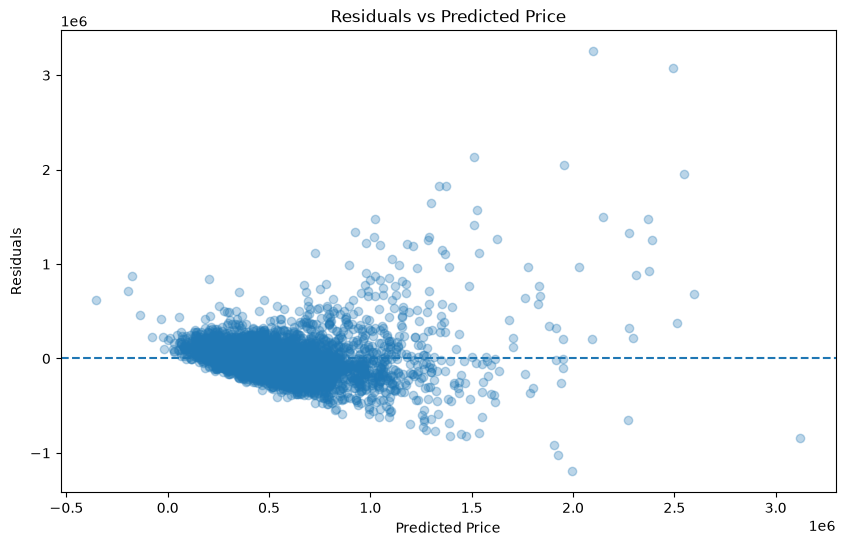

In [271]:
plt.figure(figsize=(10,6))
plt.scatter(y_pred, residual, alpha=0.3)
plt.axhline(y=0, linestyle = "--")

plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Price")

plt.show()

> **Result**: The residuals are evenly centered around 0 with no major curve, so the linearity assumption is satisfied.

### Assumption 2: Independence

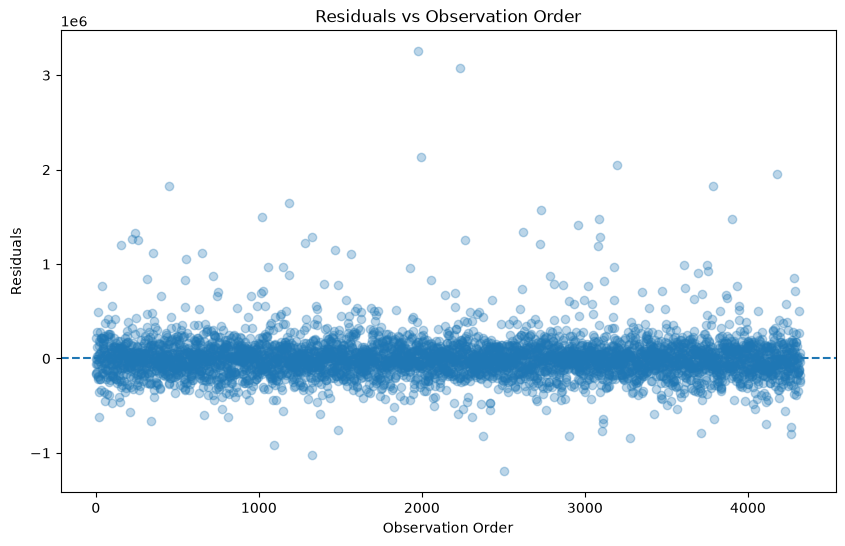

In [272]:
plt.figure(figsize=(10,6))

plt.scatter(range(len(residual)), residual, alpha=0.3)
plt.axhline(y=0, linestyle = "--")

plt.xlabel("Observation Order")
plt.ylabel("Residuals")
plt.title("Residuals vs Observation Order")

plt.show()

> **Result**: The errors are randomly distributed across the observation order with no time-based patterns.

### Assumption 3: Homoscedasticity

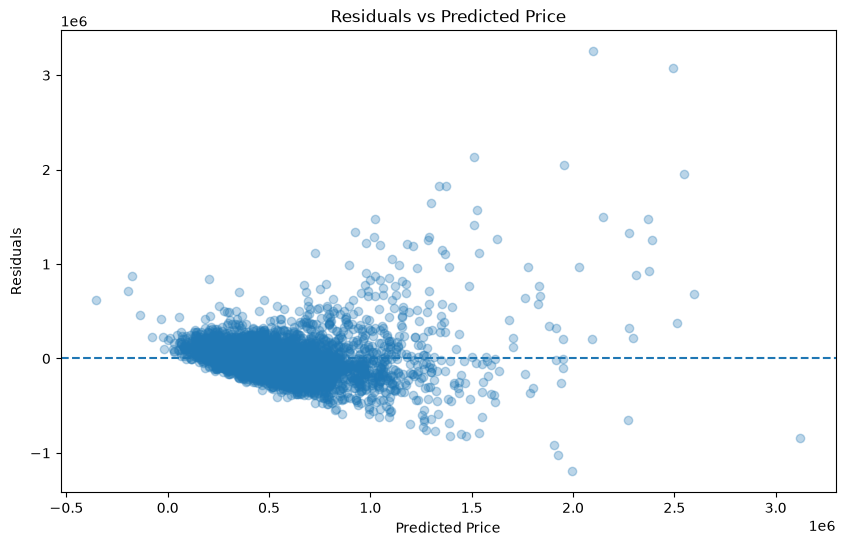

In [273]:
plt.figure(figsize=(10,6))

plt.scatter(y_pred, residual, alpha=0.3)
plt.axhline(y=0, linestyle = "--")

plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Price")

plt.show()

> **Result**: The spread of residuals gets visibly wider as predicted prices go up. Just like in simple regression, homoscedasticity is violated because high-value homes have much wider price swings.

### Assumption 4: Normality of Residuals

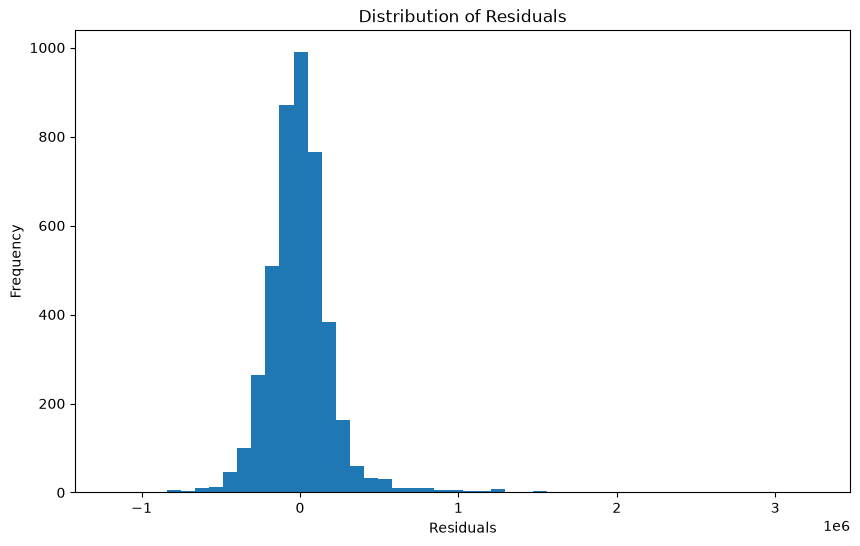

In [274]:
plt.figure(figsize=(10, 6))

plt.hist(residual, bins=50)

plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")

plt.show()

> **Result**: The error distribution has a long positive tail to the right, showing right skewness due to expensive outlier homes.

### Assumption 5: Multicollinearity (Feature Correlations and VIF)

Multicollinearity happens when features are strongly correlated with each other, which can make coefficients unstable.

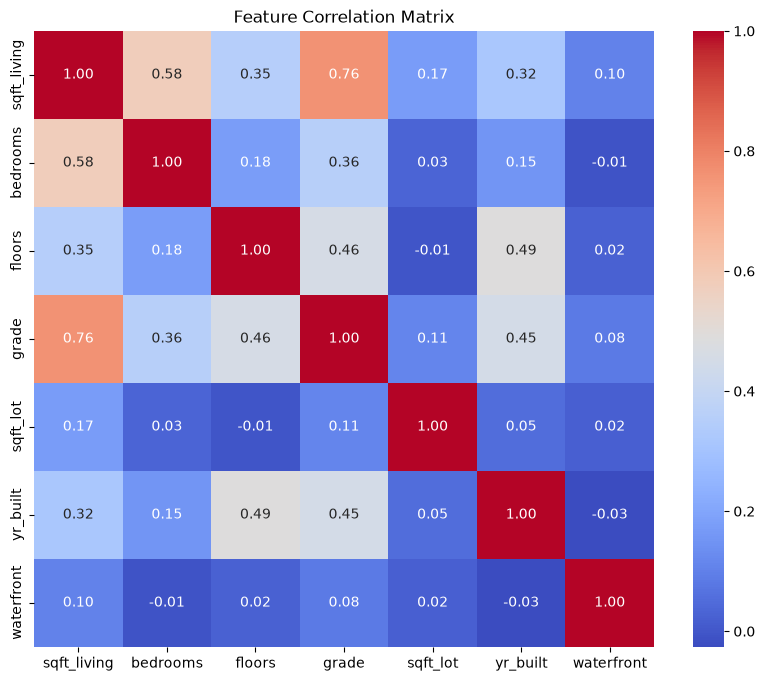

In [275]:
plt.figure(figsize=(10, 8))

sns.heatmap(X.corr(), annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Feature Correlation Matrix")
plt.show()

In [276]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()
vif_data["Feature"] = X.columns

vif_data["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print(vif_data)

       Feature       VIF
0  sqft_living  3.326329
1     bedrooms  1.559224
2       floors  1.460566
3        grade  2.868528
4     sqft_lot  1.045889
5     yr_built  1.444447
6   waterfront  1.022506


### Interpreting VIF (Variance Inflation Factor):
- VIF = 1: No correlation with other features.
- VIF between 1 and 5: Low to moderate correlation (completely safe).
- VIF > 5 or 10: High correlation that may cause coefficient instability.

**Result**: All of our features have VIF values **below 3.5** (highest is `sqft_living` at 3.33). This confirms that multicollinearity is not an issue in our feature set.

## 9. Final Assumption Summary

| Assumption | Status | Conclusion |
| :--- | :--- | :--- |
| **1. Linearity** | Passed | Residuals show no systematic curved pattern |
| **2. Independence** | Passed | Residuals are randomly scattered with no autocorrelation |
| **3. Homoscedasticity** | Violated | Error spread increases for higher-priced homes |
| **4. Normality** | Violated | Residuals are right-skewed due to luxury property outliers |
| **5. Multicollinearity** | Passed | All VIF values are under 3.5 (well below the threshold of 5) |

In the next notebook, we train this same multiple linear regression model using **Gradient Descent**.